### Computing Curvature

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, filters, measure, morphology
from skimage.color import rgb2gray
from scipy import ndimage as ndi
from scipy.signal import find_peaks
from scipy import ndimage as ndi
from skimage import segmentation, feature


In [18]:
from PIL import Image

img = np.array(Image.open('CoffeeBeans.tif'))
if img.ndim == 3:
    img = rgb2gray(img[..., :3])
img = img.astype(float)

Largest blob area: 30954.0 px


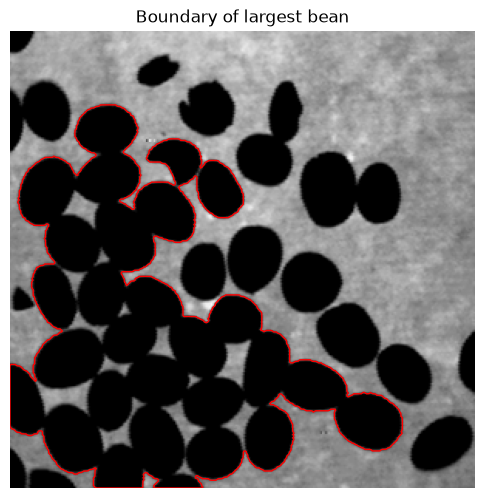

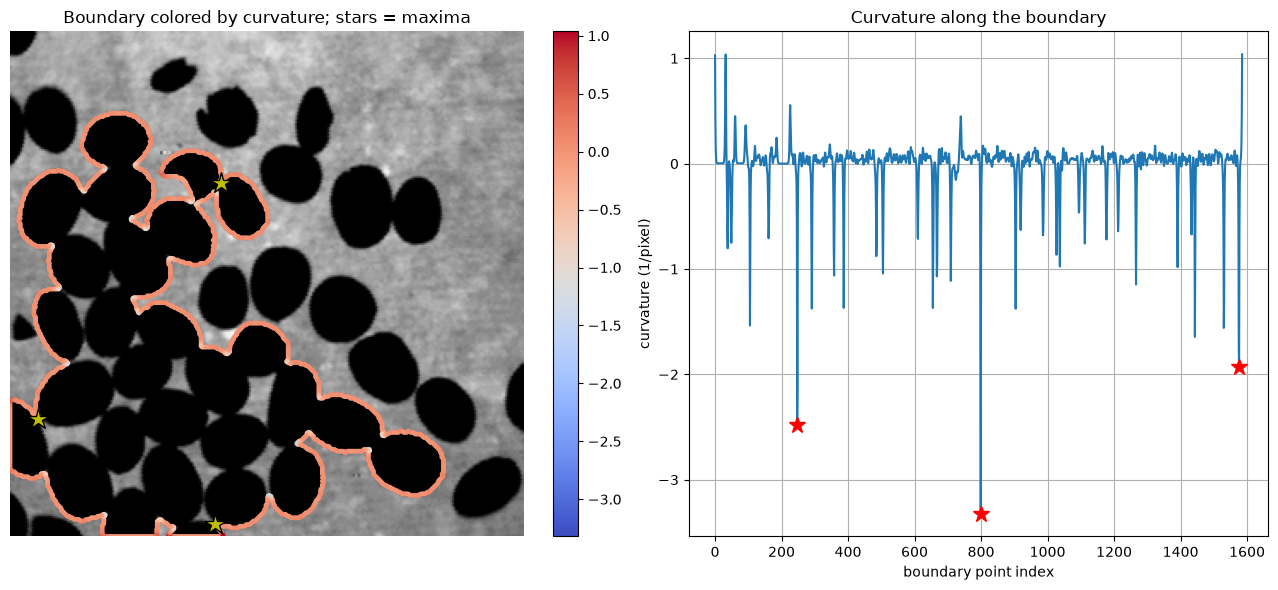

Maximum |curvature| at index 799 = 3.3211273306584737


In [19]:
# a. Threshold
t = filters.threshold_otsu(img)
mask = img > t
if mask.mean() > 0.5:          # make the beans the foreground; flip if the polarity comes out wrong
    mask = ~mask
mask = morphology.remove_small_objects(mask, max_size=50)
mask = ndi.binary_fill_holes(mask)

# b. Largest connected component
labels = measure.label(mask, connectivity=2)
largest = max(measure.regionprops(labels), key=lambda r: r.area)
blob = labels == largest.label
print(f"Largest blob area: {largest.area} px")

# c. Boundary (ordered, closed)
contours = measure.find_contours(np.pad(blob, 1).astype(float), 0.5)   # pad so it's closed
c = max(contours, key=len) - 1                                          # undo the pad offset
if np.allclose(c[0], c[-1]):
    c = c[:-1]                                                          # drop the duplicate end point
y, x = c[:, 0], c[:, 1]

# Resample to equal arc-length spacing (so index spacing = distance along the curve)
d = np.hypot(np.diff(np.r_[x, x[0]]), np.diff(np.r_[y, y[0]]))
s = np.r_[0, np.cumsum(d)]
n = int(s[-1])                                   # about one point per pixel of boundary length
s_new = np.linspace(0, s[-1], n, endpoint=False)
x = np.interp(s_new, s, np.r_[x, x[0]])
y = np.interp(s_new, s, np.r_[y, y[0]])

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray'); plt.plot(x, y, 'r-', lw=1)
plt.title('Boundary of largest bean'); plt.axis('off'); plt.show()

# d. Curvature using Gaussian derivative filters (wrap = closed curve)
def curvature(x, y, sigma=2):
    kw = dict(sigma=sigma, mode='wrap', truncate=4.5)       # truncate 4.5 -> radius 9 -> 19-point window
    x1 = ndi.gaussian_filter1d(x, order=1, **kw); y1 = ndi.gaussian_filter1d(y, order=1, **kw)
    x2 = ndi.gaussian_filter1d(x, order=2, **kw); y2 = ndi.gaussian_filter1d(y, order=2, **kw)
    return (x1 * y2 - y1 * x2) / (x1**2 + y1**2) ** 1.5

kappa = curvature(x, y, sigma=2)

# e. Stars at maxima of |curvature| (find peaks on a wrapped copy so the seam is handled)
k = np.abs(kappa)
pad = 20
kk = np.r_[k[-pad:], k, k[:pad]]
pk, _ = find_peaks(kk, height=0.5 * k.max(), distance=15)
pk = np.unique((pk - pad) % len(k))                    # map back to original indices

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].imshow(img, cmap='gray')
sc = ax[0].scatter(x, y, c=kappa, cmap='coolwarm', s=6)
ax[0].plot(x[pk], y[pk], 'y*', ms=16, mec='k')
ax[0].set_title('Boundary colored by curvature; stars = maxima'); ax[0].axis('off')
plt.colorbar(sc, ax=ax[0], fraction=0.046)
ax[1].plot(kappa); ax[1].plot(pk, kappa[pk], 'r*', ms=12)
ax[1].set_xlabel('boundary point index'); ax[1].set_ylabel('curvature (1/pixel)')
ax[1].set_title('Curvature along the boundary'); ax[1].grid(True)
plt.tight_layout(); plt.show()
print("Maximum |curvature| at index", int(np.argmax(k)), "=", k.max())

##### Rebuild the mask, then plot the 3D surface with peaks

29 regions after splitting; largest interior bean: 5001 px


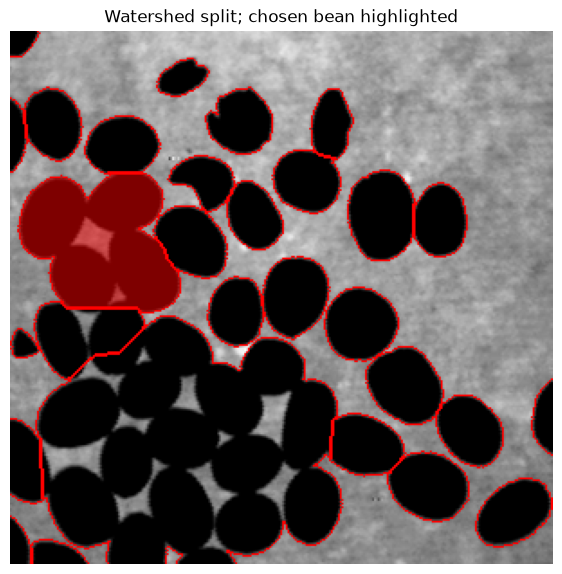

In [20]:
# Split touching beans
dist = ndi.distance_transform_edt(mask)
dist_s = filters.gaussian(dist, sigma=2)
coords = feature.peak_local_max(dist_s, min_distance=15, labels=measure.label(mask),
                                exclude_border=False)
markers = np.zeros(mask.shape, dtype=int)
markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
ws = segmentation.watershed(-dist_s, markers, mask=mask)

# Largest bean that does NOT touch the image border (a bean cut by the border has a fake edge)
H, W = mask.shape
cands = [r for r in measure.regionprops(ws)
         if r.bbox[0] > 0 and r.bbox[1] > 0 and r.bbox[2] < H and r.bbox[3] < W]
best = max(cands, key=lambda r: r.area)
print(f"{ws.max()} regions after splitting; largest interior bean: {best.area:.0f} px")

# Visual check: every region outlined, the chosen one filled
plt.figure(figsize=(7, 7))
plt.imshow(segmentation.mark_boundaries(img / img.max(), ws, color=(1, 0, 0)), cmap='gray')
plt.imshow(np.ma.masked_where(ws != best.label, ws), alpha=0.5, cmap='autumn')
plt.title('Watershed split; chosen bean highlighted'); plt.axis('off'); plt.show()

# --- Boundary of the chosen bean ---
blob = ndi.gaussian_filter((ws == best.label).astype(float), 2) > 0.5   # rounds the cut corners

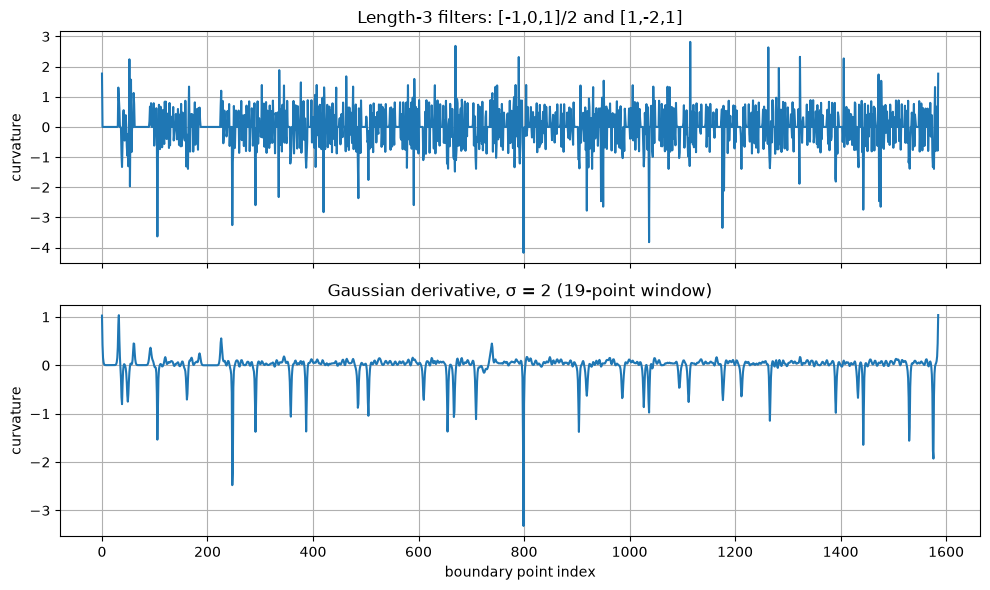

max |curvature|, 3-tap: 4.171576578586781  Gaussian: 3.3211273306584737


In [21]:
def curvature_3tap(x, y):
    # length-3 filters on a closed curve (np.roll wraps around)
    x1 = (np.roll(x, -1) - np.roll(x, 1)) / 2;  y1 = (np.roll(y, -1) - np.roll(y, 1)) / 2
    x2 = np.roll(x, -1) - 2 * x + np.roll(x, 1); y2 = np.roll(y, -1) - 2 * y + np.roll(y, 1)
    return (x1 * y2 - y1 * x2) / (x1**2 + y1**2) ** 1.5

k3 = curvature_3tap(x, y)
k_g = curvature(x, y, sigma=2)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(k3);  ax[0].set_title('Length-3 filters: [-1,0,1]/2 and [1,-2,1]')
ax[1].plot(k_g); ax[1].set_title('Gaussian derivative, σ = 2 (19-point window)')
for a in ax: a.set_ylabel('curvature'); a.grid(True)
plt.xlabel('boundary point index'); plt.tight_layout(); plt.show()
print("max |curvature|, 3-tap:", np.abs(k3).max(), " Gaussian:", np.abs(k_g).max())

In [22]:
a, b = best.major_axis_length / 2, best.minor_axis_length / 2
print(f"Ellipse prediction for peak curvature: {a / b**2:.4f}  vs measured: {np.abs(kappa).max():.4f}")

Ellipse prediction for peak curvature: 0.0337  vs measured: 3.3211


/var/folders/0m/9fw5s1v51f73ynmt361rzw380000gn/T/ipykernel_94791/3206915873.py:1: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  a, b = best.major_axis_length / 2, best.minor_axis_length / 2
/var/folders/0m/9fw5s1v51f73ynmt361rzw380000gn/T/ipykernel_94791/3206915873.py:1: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  a, b = best.major_axis_length / 2, best.minor_axis_length / 2


##### Use those peaks as the watershed markers and pick the bean

44 peaks found


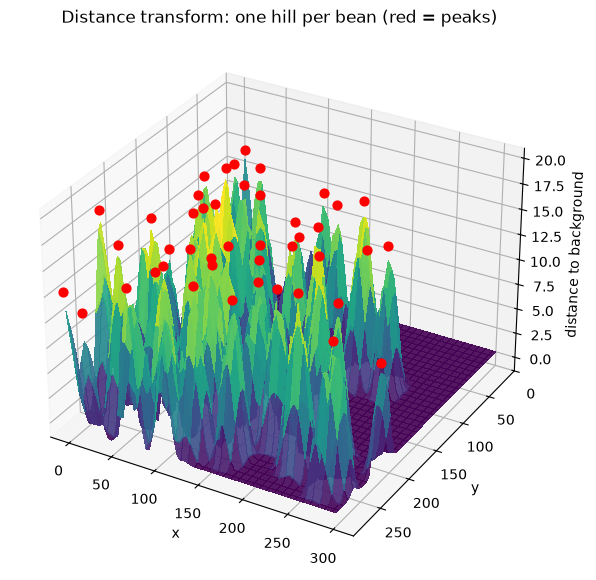

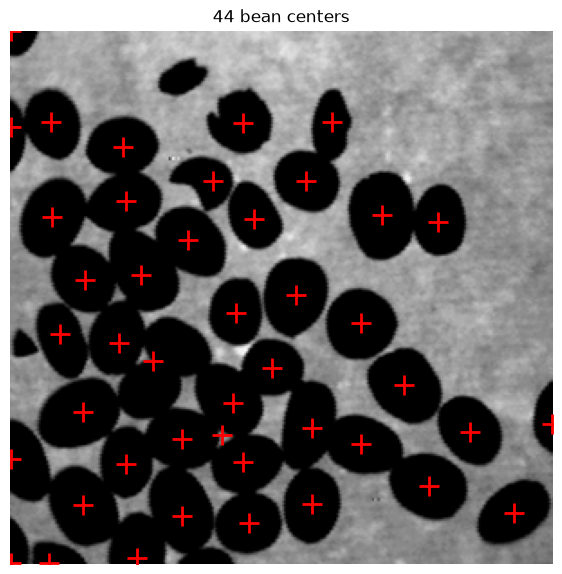

In [23]:
from mpl_toolkits.mplot3d import Axes3D
from skimage import segmentation, feature

# ebuild mask WITHOUT filling the gaps between beans
mask = img > t                        # t is the Otsu threshold from before
if mask.mean() > 0.5:
    mask = ~mask                      # beans = foreground
mask = morphology.remove_small_objects(mask, max_size=50)
mask = morphology.remove_small_holes(mask, max_size=60)   # fills specks only (older skimage: area_threshold=60)

# Distance transform = "height map": each bean becomes a peak
dist = ndi.distance_transform_edt(mask)
dist_s = filters.gaussian(dist, sigma=2)

# Peaks = bean centers
coords = feature.peak_local_max(dist_s, min_distance=12, threshold_abs=8,
                                labels=measure.label(mask), exclude_border=False)
print(f"{len(coords)} peaks found")

# 3D surface with the peaks marked
H, W = mask.shape
step = 4
Y, X = np.mgrid[0:H:step, 0:W:step]
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X, Y, dist_s[::step, ::step], cmap='viridis', linewidth=0, antialiased=False, alpha=0.9)
ax.scatter(coords[:, 1], coords[:, 0], dist_s[coords[:, 0], coords[:, 1]] + 1, c='r', s=40, depthshade=False)
ax.set_ylim(H, 0)                     # keep the image orientation
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('distance to background')
ax.set_title('Distance transform: one hill per bean (red = peaks)')
plt.show()

# Cursors at bean centers on the image 
plt.figure(figsize=(7, 7))
plt.imshow(img, cmap='gray')
plt.plot(coords[:, 1], coords[:, 0], 'r+', ms=14, mew=2)
plt.title(f'{len(coords)} bean centers'); plt.axis('off'); plt.show()

best: area = 5001 px, a = 46.5, b = 37.1, predicted peak = 0.0337
boundary centroid (x, y): 103.7 177.5 | best centroid (x, y): 50.2 117.4
step size min / median / max: 0.708 1.0 1.0
max at index 799 of 1586 -> (x, y) = 122.9 88.4


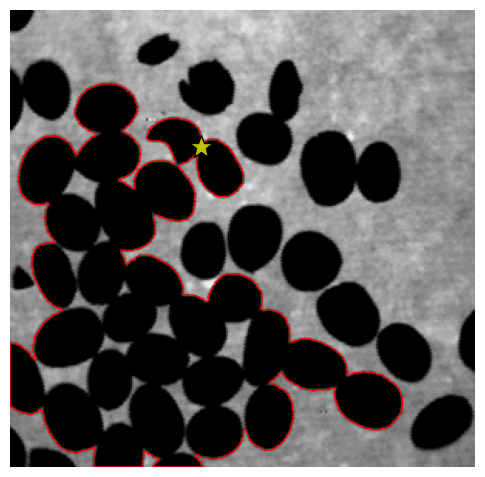

In [24]:
a, b = best.axis_major_length / 2, best.axis_minor_length / 2
print(f"best: area = {best.area:.0f} px, a = {a:.1f}, b = {b:.1f}, predicted peak = {a / b**2:.4f}")

# Do x, y belong to `best`? 
print("boundary centroid (x, y):", x.mean().round(1), y.mean().round(1),
      "| best centroid (x, y):", round(best.centroid[1], 1), round(best.centroid[0], 1))

# Duplicate points make the denominator tiny
step = np.hypot(np.diff(np.r_[x, x[0]]), np.diff(np.r_[y, y[0]]))
print("step size min / median / max:", step.min().round(3), np.median(step).round(3), step.max().round(3))

# Where is the maximum?
i = int(np.argmax(np.abs(kappa)))
print("max at index", i, "of", len(kappa), "-> (x, y) =", x[i].round(1), y[i].round(1))
plt.figure(figsize=(6, 6)); plt.imshow(img, cmap='gray'); plt.plot(x, y, 'r-', lw=1)
plt.plot(x[i], y[i], 'y*', ms=18, mec='k'); plt.axis('off'); plt.show()

isolated bean: area = 1231 px, solidity = 0.972
centroid check  boundary: 194.1 162.6 | bean: 194.1 162.5
ellipse prediction at tips: 0.0516   measured max |curvature|: 0.1344


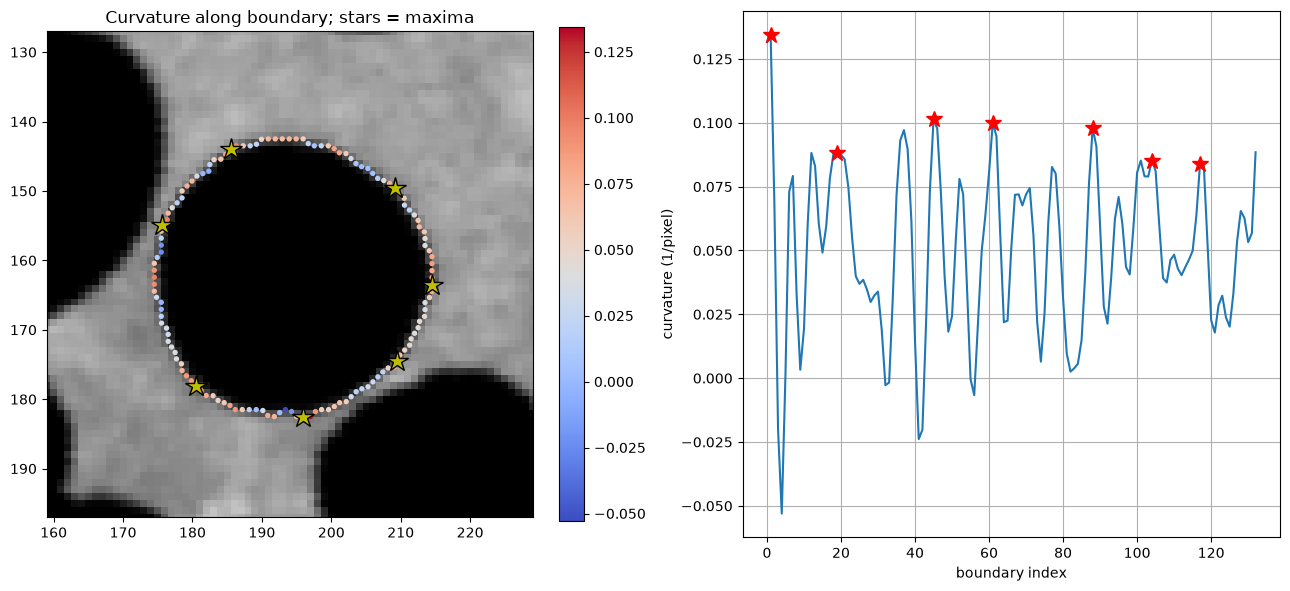

In [25]:
# Pick an isolated, nearly convex bean 
lab = measure.label(mask)
H, W = mask.shape
iso = [r for r in measure.regionprops(lab)
       if r.bbox[0] > 0 and r.bbox[1] > 0 and r.bbox[2] < H and r.bbox[3] < W and r.solidity > 0.95]
best = max(iso, key=lambda r: r.area)
blob = lab == best.label
print(f"isolated bean: area = {best.area:.0f} px, solidity = {best.solidity:.3f}")

# Boundary, resampled to equal spacing
c = max(measure.find_contours(np.pad(blob, 1).astype(float), 0.5), key=len) - 1
if np.allclose(c[0], c[-1]):
    c = c[:-1]
y, x = c[:, 0], c[:, 1]
d = np.hypot(np.diff(np.r_[x, x[0]]), np.diff(np.r_[y, y[0]]))
s = np.r_[0, np.cumsum(d)]
s_new = np.linspace(0, s[-1], int(s[-1]), endpoint=False)
x = np.interp(s_new, s, np.r_[x, x[0]]); y = np.interp(s_new, s, np.r_[y, y[0]])

# Curvature and stars
kappa = curvature(x, y, sigma=2)
k = np.abs(kappa)
pad = 20
pk, _ = find_peaks(np.r_[k[-pad:], k, k[:pad]], height=0.5 * k.max(), distance=15)
pk = np.unique((pk - pad) % len(k))

# Checks 
print("centroid check  boundary:", x.mean().round(1), y.mean().round(1),
      "| bean:", round(best.centroid[1], 1), round(best.centroid[0], 1))
a, b = best.axis_major_length / 2, best.axis_minor_length / 2
print(f"ellipse prediction at tips: {a / b**2:.4f}   measured max |curvature|: {k.max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
r0, r1 = int(y.min()) - 15, int(y.max()) + 15
c0, c1 = int(x.min()) - 15, int(x.max()) + 15
ax[0].imshow(img, cmap='gray'); ax[0].set_xlim(c0, c1); ax[0].set_ylim(r1, r0)
sc = ax[0].scatter(x, y, c=kappa, cmap='coolwarm', s=8)
ax[0].plot(x[pk], y[pk], 'y*', ms=16, mec='k'); ax[0].set_title('Curvature along boundary; stars = maxima')
plt.colorbar(sc, ax=ax[0], fraction=0.046)
ax[1].plot(kappa); ax[1].plot(pk, kappa[pk], 'r*', ms=12); ax[1].grid(True)
ax[1].set_xlabel('boundary index'); ax[1].set_ylabel('curvature (1/pixel)')
plt.tight_layout(); plt.show()
##### Choosing a more elongdated bean

##### Choosing an elongated bean

In [26]:
iso = [r for r in measure.regionprops(lab)
       if r.bbox[0] > 0 and r.bbox[1] > 0 and r.bbox[2] < H and r.bbox[3] < W and r.solidity > 0.95]
best = max(iso, key=lambda r: r.axis_major_length / r.axis_minor_length)
print(f"area = {best.area:.0f}, axis ratio = {best.axis_major_length / best.axis_minor_length:.2f}")
blob = lab == best.label

area = 1098, axis ratio = 1.50


##### Smooth more, and fix the seam.

σ=2: max |κ| = 0.1344, mean κ = 0.0507
σ=4: max |κ| = 0.0746, mean κ = 0.0515
σ=6: max |κ| = 0.0675, mean κ = 0.0526


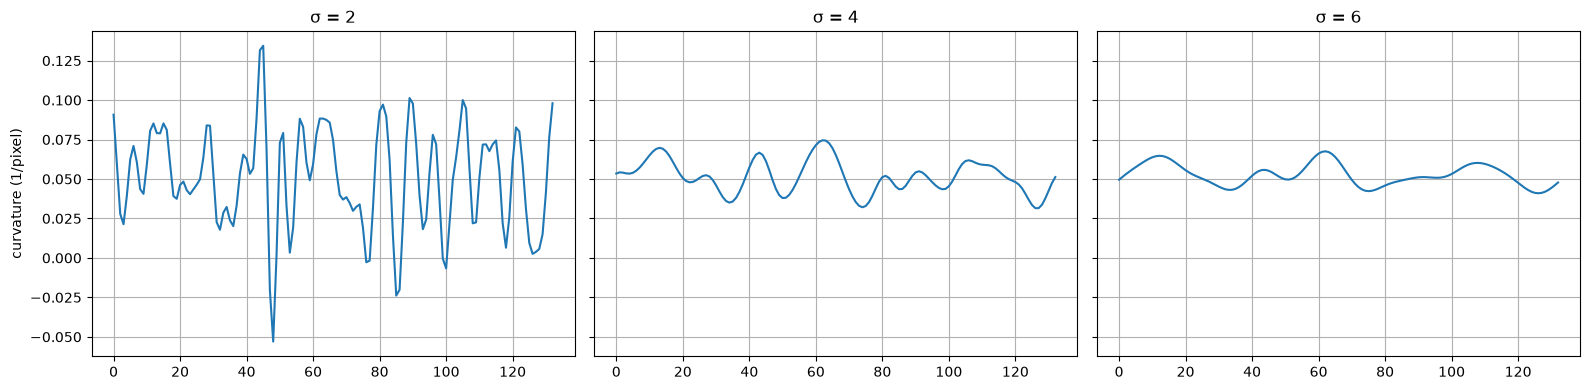

In [27]:
# after resampling, rotate the start point to the middle of the long side
x = np.roll(x, len(x) // 3); y = np.roll(y, len(y) // 3)

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, sg in zip(ax, [2, 4, 6]):
    kap = curvature(x, y, sigma=sg)
    a.plot(kap); a.set_title(f'σ = {sg}'); a.grid(True)
    print(f"σ={sg}: max |κ| = {np.abs(kap).max():.4f}, mean κ = {kap.mean():.4f}")
ax[0].set_ylabel('curvature (1/pixel)')
plt.tight_layout(); plt.show()

In [28]:
ds = np.hypot(np.diff(np.r_[x, x[0]]), np.diff(np.r_[y, y[0]])).mean()
for sg in [2, 4, 6]:
    print(f"σ={sg}: total turning = {(curvature(x, y, sg) * ds).sum():.2f}  (2π = {2*np.pi:.2f})")

σ=2: total turning = 6.61  (2π = 6.28)
σ=4: total turning = 6.71  (2π = 6.28)
σ=6: total turning = 6.86  (2π = 6.28)


In [29]:
for sg in [2, 4, 6]:
    xs = ndi.gaussian_filter1d(x, sg, mode='wrap')
    ys = ndi.gaussian_filter1d(y, sg, mode='wrap')
    ds_s = np.hypot(np.diff(np.r_[xs, xs[0]]), np.diff(np.r_[ys, ys[0]]))   # actual step of the smoothed curve
    kap = curvature(x, y, sigma=sg)
    print(f"σ={sg}: total turning = {(kap * ds_s).sum():.3f}  (2π = {2*np.pi:.3f})")

σ=2: total turning = 6.308  (2π = 6.283)
σ=4: total turning = 6.293  (2π = 6.283)
σ=6: total turning = 6.286  (2π = 6.283)
